# D07. Trực quan hóa cụm cho DBSCAN và Incremental DBSCAN

*Dữ liệu mô phỏng (không phải dữ liệu ngân hàng thật). Mọi hình gom cụm lấy từ code tự cài của nhóm (`src/clustering/dbscan.py` và `src/clustering/incremental_dbscan.py`). sklearn chỉ dùng làm đối chứng: DBSCAN của sklearn ở mục 7, KMeans và HAC ở mục 8.*

**Thuộc yêu cầu nào.** Mục 2.1 của yêu cầu đồ án (minh họa trong không gian 2D), cùng hình cho mục 1.2 (ví dụ từng bước) và 1.3 (so với thuật toán khác).

**Cách dùng.** `ClusterVisualizer` vẽ một *snapshot* (ids, coords, labels, point_types), không vẽ trực tiếp một lớp thuật toán. Engine là `IncrementalEngine` (`src/experiments/engine.py`): chính `IncrementalDBSCAN` của nhóm, chỉ thêm `snapshot()` để bộ vẽ đọc được. Mỗi hình sau một insert hoặc delete là trạng thái do thuật toán gia tăng tạo ra, không phải do fit lại. Mọi hình là kết quả chạy thật trên các kịch bản và stream trong `data/`, không vẽ tay.

**Thời gian chạy.** Khoảng 1 phút trên laptop của TV4 (mục 7 không còn fit lại sau mỗi update).

---
#### **0. THƯ VIỆN VÀ ĐƯỜNG DẪN**

In [1]:
## Thư viện và thư mục gốc repo (chạy từ gốc repo hay từ notebooks/ đều được)
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def repo_root(start=None):
    here = Path(start or Path.cwd()).resolve()
    for d in (here, *here.parents):
        if (d / 'src' / 'visualization').is_dir():
            return d
    raise FileNotFoundError('không thấy src/visualization: hãy mở notebook bên trong repo')


os.chdir(repo_root())
from src.experiments.engine import IncrementalEngine
from baseline.sklearn_dbscan import RefitDBSCAN, ambiguous_by_step, compare_partitions, read_stream, replay_stream
from src.preprocessing.stream_scaling import feature_columns
from src.visualization import (ClusterVisualizer, equivalence_series, label_changes, load_scenario, plot_affected_points,
                               plot_algorithm_contrast, plot_equivalence_timeline, plot_k_distance, plot_runtime_comparison,
                               plot_scaling_effect, project_2d, run_scenario, snapshot_from_model, stream_snapshots, type_counts)
from src.visualization.animation import animate_stream
from src.visualization.gallery import build_gallery_cases
pd.set_option('display.max_columns', None); pd.set_option('display.width', 200)

In [2]:
## Engine cho mọi hình: IncrementalDBSCAN của nhóm (qua IncrementalEngine, hàm tạo nhận eps, min_pts)
ENGINE = IncrementalEngine
FIG = Path('report/figures'); FIG.mkdir(parents=True, exist_ok=True)
vis = ClusterVisualizer()
print(ENGINE.__name__, FIG)

IncrementalEngine report/figures


---
#### **1. SNAPSHOT: CẦU NỐI GIỮA MỌI MÔ HÌNH VÀ BỘ VẼ**

In [3]:
## Đọc kịch bản toy R02 Case 4 (Merge): 12 điểm, Eps 1,1, MinPts 4
sc = load_scenario('toy', 'r02_4_merge')
print(sc['names'], sc['eps'], sc['min_pts'])

['A1', 'A2', 'A3', 'A4', 'A5', 'A6', 'B1', 'B2', 'B3', 'B4', 'B5', 'B6'] 1.1 4


In [4]:
## Fit engine trên 12 điểm đầu
eng = ENGINE(sc['eps'], sc['min_pts']).fit(sc['coords'])
print(eng.n_points, eng.n_clusters, eng.n_noise)

12 2 0


In [5]:
## Adapter duy nhất từ mô hình sang snapshot (ids, coords, labels, point_types)
snap = snapshot_from_model(eng)
print({k: v.shape for k, v in snap.items()})

{'ids': (12,), 'coords': (12, 2), 'labels': (12,), 'point_types': (12,)}


In [6]:
## Xem snapshot dạng bảng (mã loại điểm: 3 là lõi, 2 là biên, 1 là nhiễu)
pd.DataFrame({'id': snap['ids'], 'x': snap['coords'][:, 0], 'y': snap['coords'][:, 1], 'nhãn': snap['labels'], 'loại': snap['point_types']}).head(6)

,id,x,y,nhãn,loại
0,0,-1.0,0.0,0,2
1,1,0.0,0.0,0,3
2,2,1.0,0.0,0,2
3,3,-1.0,1.0,0,2
4,4,0.0,1.0,0,3
5,5,1.0,1.0,0,2


In [7]:
## Đếm lõi, biên, nhiễu và số cụm
type_counts(snap)

{'core': 4, 'border': 8, 'noise': 0, 'other': 0, 'clusters': 2, 'n': 12}

---
#### **2. plot_2d: MỘT SNAPSHOT**

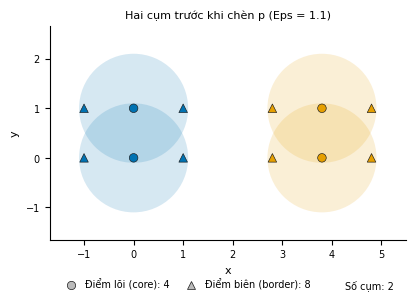

In [8]:
## plot_2d có Eps: vùng tô là hợp hình tròn Eps quanh điểm lõi
ax = vis.plot_2d(snap, eps=sc['eps'], title='Hai cụm trước khi chèn p (Eps = 1.1)')

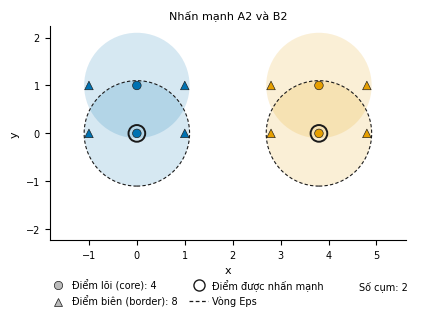

In [9]:
## plot_2d nhấn mạnh hai điểm lõi (id 1 và 7 của snapshot, tức A2 và B2) bằng vòng và đường tròn Eps
ax = vis.plot_2d(snap, eps=sc['eps'], highlight_ids=[1, 7], title='Nhấn mạnh A2 và B2')

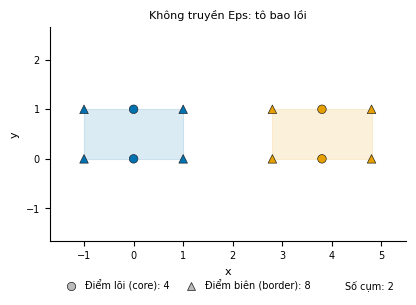

In [10]:
## plot_2d không biết Eps: vùng tô là bao lồi của từng cụm
ax = vis.plot_2d(snap, title='Không truyền Eps: tô bao lồi', fill='hull')

---
#### **3. plot_before_after: CHÈN VÀ XÓA**

In [11]:
## Chạy kịch bản Merge: chèn p, lấy snapshot trước và sau
run = run_scenario(ENGINE, sc)
print(run['update'], run['seed_ids'])

[{'op': 'insert', 'point_id': 'p', 'coords': array([1.9, 0.5])}] ['A2', 'A3', 'A5', 'A6', 'B1', 'B2', 'B4', 'B5', 'p']


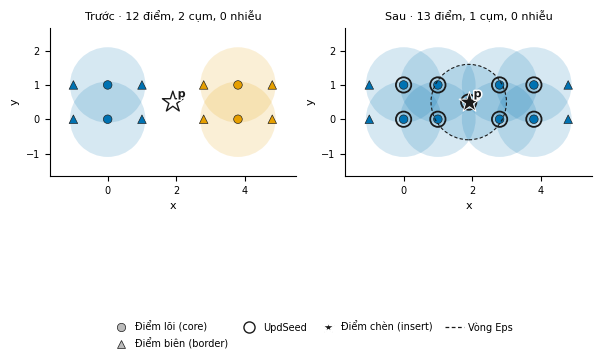

In [12]:
## Trước và sau khi chèn p; sao đặc là điểm chèn, vòng đen là UpdSeed
fig = vis.plot_before_after(run['before'], run['after'], run['update'], eps=run['eps'], seed_ids=run['seed_ids'])

In [13]:
## Kiểm tra khớp expected.json (phân hoạch sau update)
exp = sc['expected']['labels_after']
compare_partitions(dict(zip(run['after']['ids'], run['after']['labels'])), exp)['partition_equal']

True

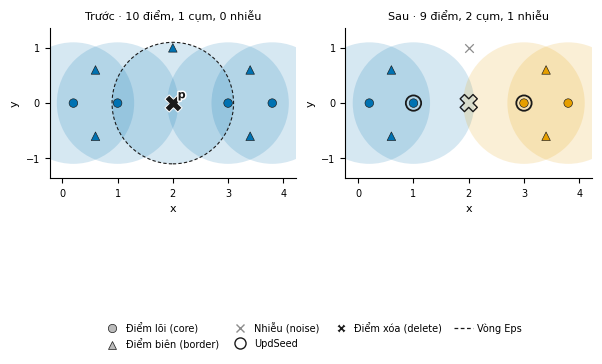

In [14]:
## Ca xóa: R03 Case 3A (Split); dấu X đặc là điểm bị xóa, dấu X rỗng là vị trí cũ
sc3 = load_scenario('toy', 'r03_3a_split'); run3 = run_scenario(ENGINE, sc3)
fig = vis.plot_before_after(run3['before'], run3['after'], run3['update'], eps=run3['eps'], seed_ids=run3['seed_ids'])

---
#### **4. DỮ LIỆU NHIỀU CHIỀU: PCA BẰNG SVD**

In [15]:
## Kịch bản 4 chiều e18: chạy trên engine
sc18 = load_scenario('toy_edge', 'e18_insert_4d_merge'); run18 = run_scenario(ENGINE, sc18)
print(run18['before']['coords'].shape, run18['update'][0]['op'])

(13, 4) insert


In [16]:
## project_2d: tọa độ chiếu và tỉ lệ phương sai của hai thành phần chính
proj, explained = project_2d(run18['after']['coords'])
print(proj.shape, explained.round(3), explained.sum().round(3))

(14, 2) [0.862 0.131] 0.993


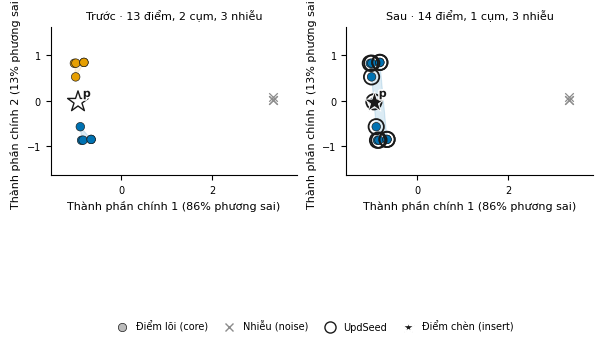

In [17]:
## plot_before_after tự chiếu PCA chung một hệ trục cho cả hai panel (không vẽ Eps vì khoảng cách bị biến dạng)
fig = vis.plot_before_after(run18['before'], run18['after'], run18['update'], seed_ids=run18['seed_ids'])

In [18]:
## Dữ liệu thẻ 5 chiều đã chuẩn hóa: DBSCAN của nhóm với Eps 0,4 và MinPts 6 (tham số stream thẻ)
card = pd.read_csv('data/processed/card_txn_5d_scaled.csv')
zcols = [c for c in card.columns if c.endswith('_z')]
card_eng = ENGINE(0.4, 6).fit(card[zcols].to_numpy())
print(zcols, card_eng.n_points, 'điểm |', card_eng.n_clusters, 'cụm |', card_eng.n_noise, 'nhiễu')

['log10_amount_vnd_z', 'hour_of_day_z', 'distance_from_home_km_z', 'txns_last_7d_z', 'merchant_risk_score_z'] 1492 điểm | 4 cụm | 21 nhiễu


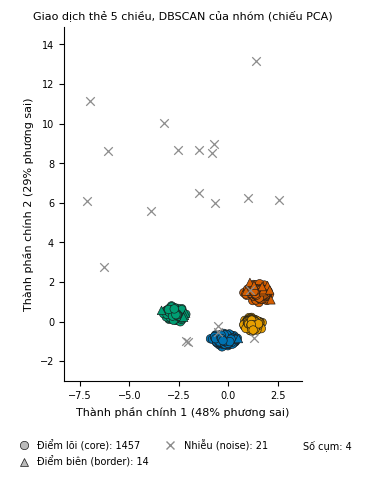

In [19]:
## plot_2d trên 5 chiều: tự chiếu PCA, nhãn trục ghi phần phương sai
card_snap = {**snapshot_from_model(card_eng), 'ids': card['txn_id'].to_numpy()}
ax = vis.plot_2d(card_snap, title='Giao dịch thẻ 5 chiều, DBSCAN của nhóm (chiếu PCA)')

---
#### **5. BỘ ẢNH CÁC TRƯỜNG HỢP CHÈN VÀ XÓA (TOY)**

In [20]:
## Dựng 8 kịch bản toy trên engine, Eps 1,1 và MinPts 4, UpdSeed lấy từ expected.json
toy_cases = build_gallery_cases('toy', ENGINE)
print([c['header'] for c in toy_cases])

['1. Noise', '2. Creation', '3. Absorption', '4. Merge', '5. Removal', '6. Reduction', '7a. Split', '7b. Non-split']


In [21]:
## Kiểm tra mỗi kịch bản: phân hoạch sau update khớp expected.json
[compare_partitions(dict(zip(c['after']['ids'], c['after']['labels'])), c['expected']['labels_after'])['partition_equal'] for c in toy_cases]

[True, True, True, True, True, True, True, True]

report/figures/case_gallery_insert_delete.png


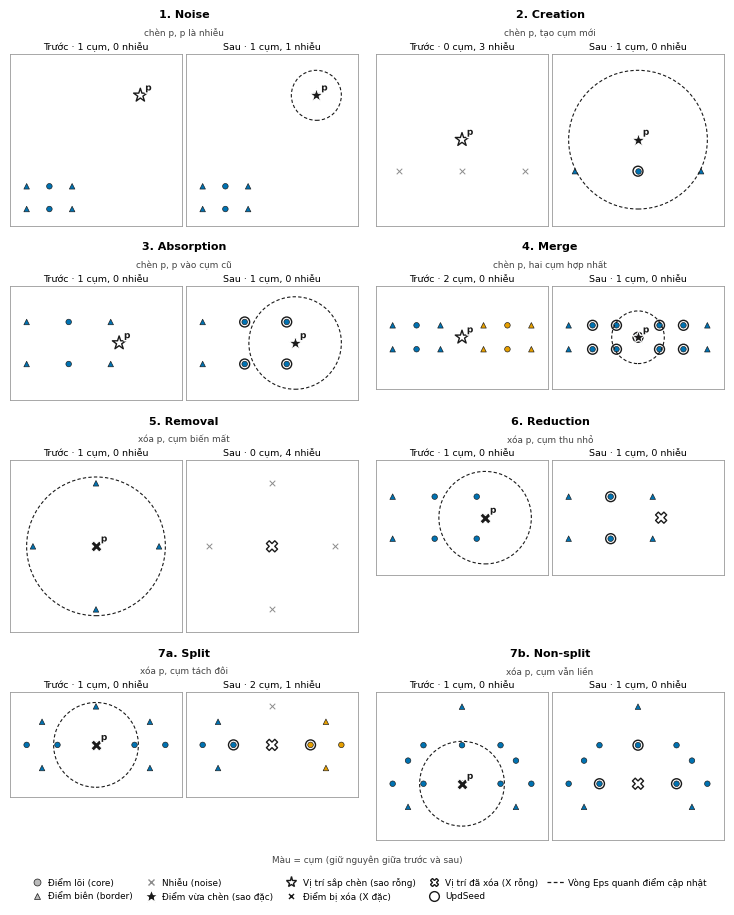

In [22]:
## Vẽ và lưu case_gallery_insert_delete.png (rộng 7,5 inch, vừa A4)
fig = vis.plot_case_gallery(toy_cases, n_pair_cols=2, fill=None)
print(vis.save(fig, FIG / 'case_gallery_insert_delete.png'))

---
#### **6. BỘ ẢNH 19 KỊCH BẢN BIÊN (TOY_EDGE)**

In [23]:
## Dựng 19 kịch bản biên; nhiều dòng update thì hình là trạng thái cuối
edge_cases = build_gallery_cases('toy_edge', ENGINE)
print(len(edge_cases), [c['header'] for c in edge_cases][:4])

19 ['e01 Absorption', 'e02 Noise', 'e03 Creation', 'e04 Creation']


In [24]:
## Kiểm tra 19 kịch bản biên: phân hoạch cuối khớp expected.json (bỏ điểm biên mơ hồ ghi trong expected.json)
[compare_partitions(dict(zip(c['after']['ids'], c['after']['labels'])), c['expected']['labels_after'],
                    ignore_ids=c['expected'].get('ambiguous_to_ignore', []))['partition_equal'] for c in edge_cases].count(True)

19

report/figures/case_gallery_edge.png


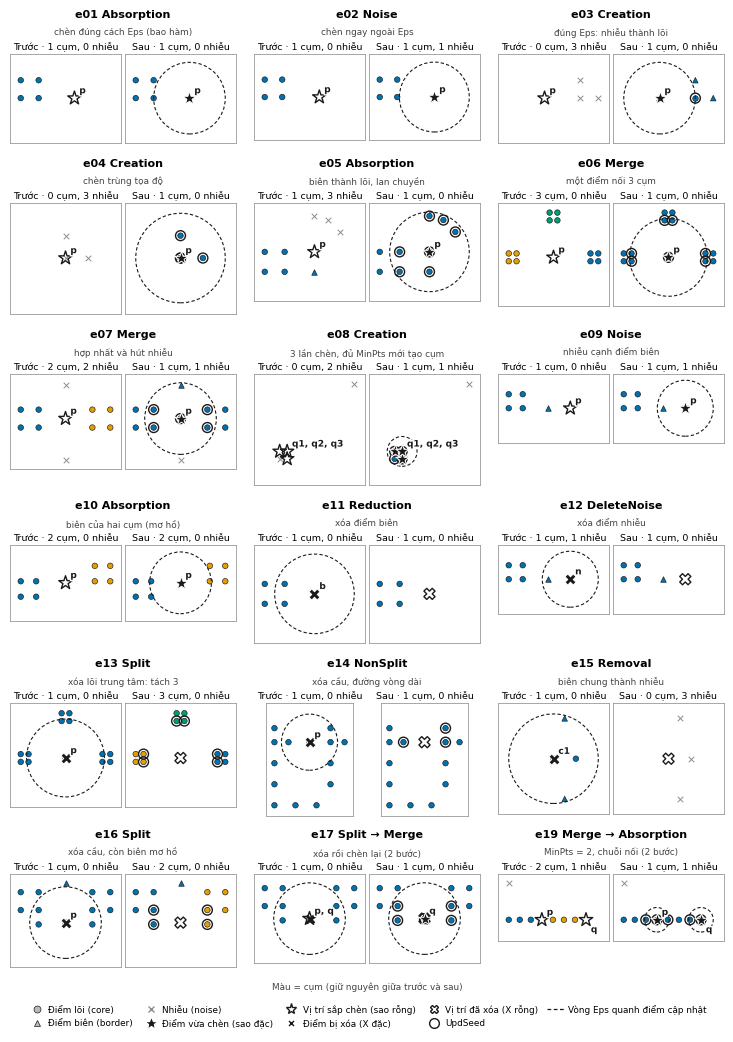

In [25]:
## Vẽ và lưu case_gallery_edge.png: 18 kịch bản 2 chiều, ba cặp mỗi hàng (e18 là 4 chiều, đã vẽ riêng bằng PCA ở mục 4)
fig = vis.plot_case_gallery([c for c in edge_cases if c['name'] != 'e18_insert_4d_merge'], n_pair_cols=3, fill=None)
print(vis.save(fig, FIG / 'case_gallery_edge.png'))

---
#### **7. STREAM: TÍNH TƯƠNG ĐƯƠNG, THỜI GIAN, SỐ ĐIỂM BỊ ẢNH HƯỞNG**

*Engine là IncrementalDBSCAN của nhóm, cập nhật từng điểm; đối chứng là DBSCAN của sklearn chạy cùng stream (`RefitDBSCAN`). ARI bằng 1 ở mọi step nghĩa là code tự cài cho cùng kết quả với thư viện qua 719 lần cập nhật (119 + 300 + 300). Điểm biên mơ hồ (stream thẻ khó có ở mọi step) được bỏ ra trước khi so. Bản cố ý làm lệch ở dưới chứng minh đường ống đo bắt được sai lệch.*

In [26]:
## Chạy ba stream bằng engine của nhóm và bằng sklearn (đối chứng); mỗi update đo 3 lần trên bản sao, lấy trung vị
streams = {'atm_stream': 'bank_geo', 'card_stream': 'bank_card', 'card_stream_hard': 'bank_card'}
replay = {}
for name, folder in streams.items():
    d0, upd, params, feats = read_stream(f'data/raw/{folder}/{name}')
    timing, labels = replay_stream(ENGINE, d0, upd, params, feats, repeats=3)
    ref_timing, ref = replay_stream(RefitDBSCAN, d0, upd, params, feats, repeats=3)
    replay[name] = (timing, labels, ref, ref_timing, ambiguous_by_step(params, upd))
    print(name, len(timing) - 1, 'update')

atm_stream 119 update


card_stream 300 update


card_stream_hard 300 update


In [27]:
## ARI từng step so với sklearn, bỏ điểm biên mơ hồ: (số step, ARI nhỏ nhất, tổng số lượt điểm bị bỏ)
eq = {n: equivalence_series(lab, ref, compare_partitions, ambiguous=amb) for n, (_, lab, ref, _, amb) in replay.items()}
{n: (len(e), e['ari'].min(), int(e['n_ignored'].sum())) for n, e in eq.items()}

{'atm_stream': (120, np.float64(1.0), 0),
 'card_stream': (301, np.float64(1.0), 0),
 'card_stream_hard': (301, np.float64(1.0), 984)}

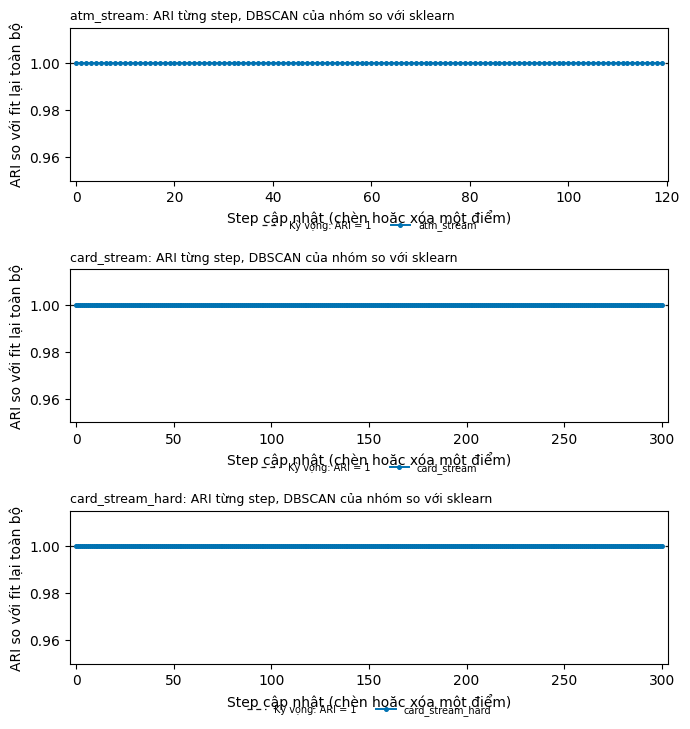

In [28]:
## Dòng thời gian tương đương của ba stream: kỳ vọng phẳng ở 1,0
fig, axes = plt.subplots(3, 1, figsize=(7.0, 7.4))
for ax, (n, e) in zip(axes, eq.items()):
    plot_equivalence_timeline(e.assign(series=n), ax=ax, title=f'{n}: ARI từng step, DBSCAN của nhóm so với sklearn')
fig.tight_layout()

In [29]:
## Cố ý làm lệch bản sao nhãn: gán bậy 40 điểm ở step 30, 31, 70 của stream ATM
timing_atm, lab_atm, ref_atm, ref_timing_atm, _ = replay['atm_stream']
bad = ref_atm.copy(); rng = np.random.default_rng(0)
for s in (30, 31, 70):
    idx = bad.index[bad['step'] == s][:40]
    bad.loc[idx, 'label'] = rng.integers(0, 3, len(idx))
eq_bad = equivalence_series(lab_atm, bad, compare_partitions)
eq_bad[eq_bad['ari'] < 1].round(3)

,step,ari,n_compared,n_ignored
30,30,0.833,535,0
31,31,0.840,536,0
70,70,0.853,541,0


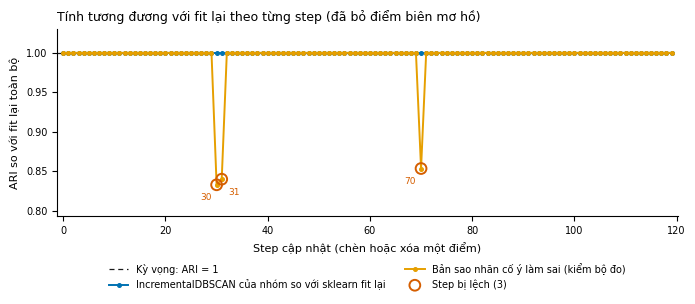

In [30]:
## Dòng thời gian có hai đường: đúng và cố ý làm lệch; step lệch được khoanh đỏ
both = pd.concat([eq['atm_stream'].assign(series='IncrementalDBSCAN của nhóm so với sklearn fit lại'), eq_bad.assign(series='Bản sao nhãn cố ý làm sai (kiểm bộ đo)')])
fig = plot_equivalence_timeline(both)
fig.savefig(FIG / 'equivalence_timeline_demo.png', dpi=200, bbox_inches='tight')

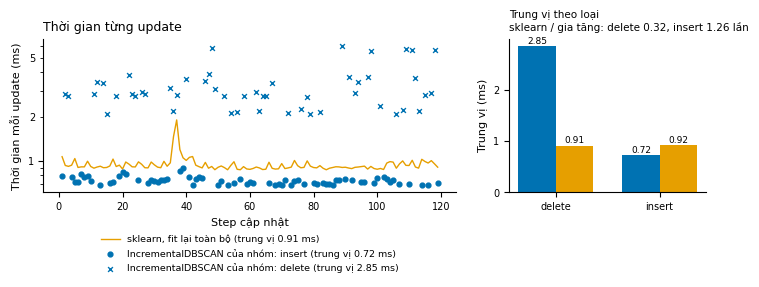

In [31]:
## Thời gian mỗi update trên stream ATM: IncrementalDBSCAN của nhóm và sklearn fit lại (trung vị 3 lần đo mỗi update; benchmark đầy đủ ở D09)
fig = plot_runtime_comparison(timing_atm, ref_timing_atm, labels=('IncrementalDBSCAN của nhóm', 'sklearn, fit lại toàn bộ'), ratio_label='sklearn / gia tăng')
fig.savefig(FIG / 'runtime_incremental_vs_sklearn_atm.png', dpi=200, bbox_inches='tight')

In [32]:
## Số điểm đổi cụm mỗi update (không tính điểm chèn hoặc xóa); D05 và D06 đo thêm UpdSeed và số điểm phép xóa xử lý lại
affected = label_changes(lab_atm, timing_atm)
affected.groupby('op')['n_affected'].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
op,,,,,,,,
delete,50.0,1.80,2.47,0.0,0.0,0.0,4.0,6.0
insert,69.0,1.61,2.26,0.0,0.0,0.0,4.0,6.0


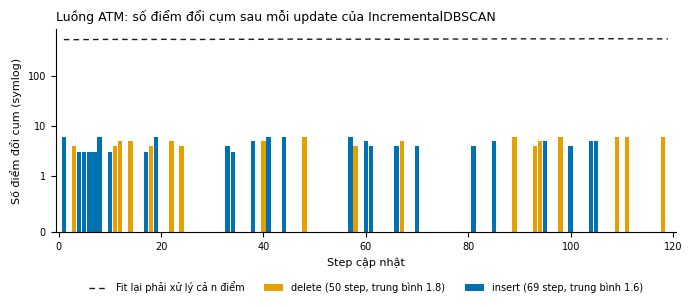

In [33]:
## Biểu đồ số điểm bị ảnh hưởng so với n (fit lại phải xử lý cả n điểm)
fig = plot_affected_points(affected, title='Luồng ATM: số điểm đổi cụm sau mỗi update của IncrementalDBSCAN')
fig.savefig(FIG / 'affected_points_demo.png', dpi=200, bbox_inches='tight')

---
#### **8. HÌNH CHO BÁO CÁO: SO THUẬT TOÁN, K-DISTANCE, CHUẨN HÓA**

In [34]:
## Bản đồ ATM 2D (km) và nhãn thật hotspot
atm = pd.read_csv('data/raw/bank_geo/atm_txn_2d.csv')
xy = atm[['x_km', 'y_km']].to_numpy(); truth = atm['hotspot_id'].to_numpy()
print(xy.shape, sorted(set(truth)))

(1200, 2) [np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


In [35]:
## KMeans và HAC Ward của sklearn (thuật toán khác, chỉ để so sánh) cạnh DBSCAN của nhóm
from sklearn.cluster import AgglomerativeClustering, KMeans
labels_by_algo = {'KMeans (k = 6)': KMeans(6, n_init=10, random_state=0).fit_predict(xy),
                  'HAC Ward (k = 6)': AgglomerativeClustering(6, linkage='ward').fit_predict(xy),
                  'DBSCAN của nhóm (Eps = 0.5 km, MinPts = 4)': np.array(ENGINE(0.5, 4).fit(xy).get_labels())}
scores = {k: compare_partitions(v, truth)['ari'] for k, v in labels_by_algo.items()}
{k: round(v, 3) for k, v in scores.items()}

{'KMeans (k = 6)': 0.583,
 'HAC Ward (k = 6)': 0.544,
 'DBSCAN của nhóm (Eps = 0.5 km, MinPts = 4)': 0.993}

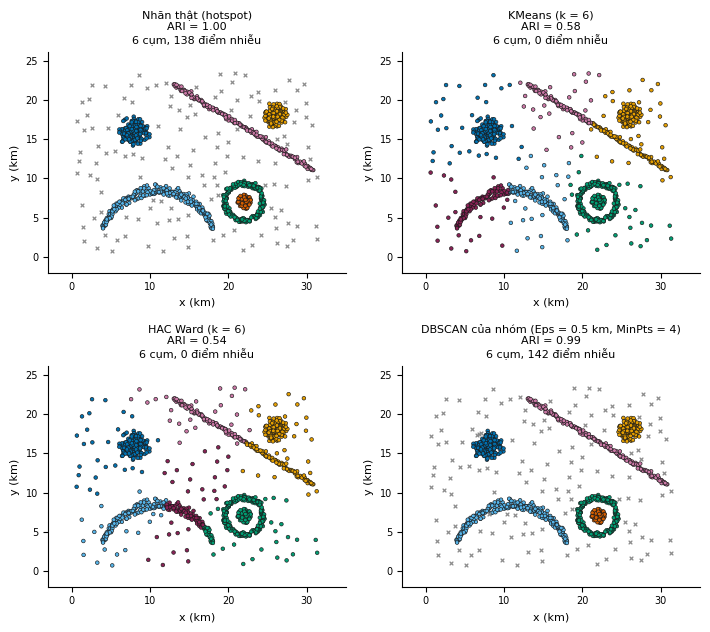

In [36]:
## Ba thuật toán cạnh nhãn thật trên cùng bản đồ (ARI trong tiêu đề)
fig = plot_algorithm_contrast(xy, truth, labels_by_algo, scores={'Nhãn thật (hotspot)': 1.0, **scores})
fig.savefig(FIG / 'algorithm_contrast_atm.png', dpi=200, bbox_inches='tight')

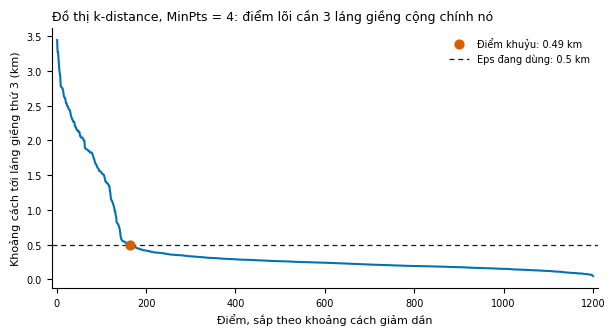

In [37]:
## k-distance của bản đồ ATM (MinPts 4, khoảng cách tính bằng numpy); khuỷu gần Eps 0,5 km đang dùng
fig = plot_k_distance(xy, min_pts=4, eps=0.5)
fig.savefig(FIG / 'k_distance_atm.png', dpi=200, bbox_inches='tight')

In [38]:
## Trước và sau chuẩn hóa của bảng thẻ: năm cột thô (đã làm sạch) và năm cột z-score
clean = pd.read_csv('data/processed/card_txn_5d_clean.csv')
feat = ['amount_vnd', 'hour_of_day', 'distance_from_home_km', 'txns_last_7d', 'merchant_risk_score']
print((clean['txn_id'] == card['txn_id']).all(), zcols)

True ['log10_amount_vnd_z', 'hour_of_day_z', 'distance_from_home_km_z', 'txns_last_7d_z', 'merchant_risk_score_z']


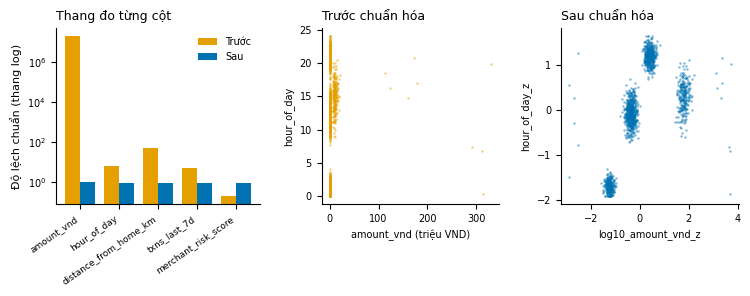

In [39]:
## Độ lệch chuẩn từng cột (log) và tán xạ số tiền với giờ, trước và sau chuẩn hóa
fig = plot_scaling_effect(clean[feat], card[zcols], pair=(0, 1), names=feat, names_after=zcols, units={0: (1e6, 'triệu VND')})
fig.savefig(FIG / 'scaling_effect_card.png', dpi=200, bbox_inches='tight')

---
#### **9. HOẠT ẢNH STREAM ATM**

In [40]:
## Phát lại stream ATM trên engine, giữ snapshot từng step
frames = stream_snapshots(ENGINE, 'data/raw/bank_geo/atm_stream')
print(len(frames), frames[1]['op'], frames[1]['case'])

120 insert Merge


In [41]:
## Ghi atm_stream.gif (Pillow, 600 px rộng, một khung mỗi step)
gif = animate_stream(frames, FIG / 'atm_stream.gif')
print(gif, round(os.path.getsize(gif) / 1e6, 2), 'MB')

report/figures/atm_stream.gif 3.23 MB


![Stream ATM](../report/figures/atm_stream.gif)

---
#### **10. KẾT LUẬN**

- **Mọi hình lấy từ thuật toán gia tăng thật.** Engine là `IncrementalDBSCAN` của nhóm (qua `IncrementalEngine`). 8 kịch bản toy và 19 kịch bản biên đều khớp đáp án trong `expected.json` (mục 5 và 6); UpdSeed vẽ trong hình lấy từ đáp án và trùng với UpdSeed tính từ kết quả của engine ở cả 31 bước (D05, D06).
- **Giống sklearn qua 719 lần cập nhật.** Ba stream (119, 300 và 300 update) cho ARI bằng 1 ở mọi step so với sklearn fit lại, sau khi bỏ 984 lượt điểm biên mơ hồ của stream thẻ khó (mục 7).
- **Tốc độ trên stream ATM (khoảng 530 điểm).** Một insert của bản gia tăng mất khoảng 0,7 ms, nhanh hơn sklearn fit lại (khoảng 0,9 ms) một chút; một delete mất khoảng 3 ms, chậm hơn sklearn. So với DBSCAN của nhóm fit lại (khoảng 370 ms mỗi lần), bản gia tăng nhanh hơn hàng trăm lần. Số liệu đầy đủ theo n và theo số update ở D09.
- **So với thuật toán khác (mục 8).** Trên bản đồ ATM, DBSCAN của nhóm đạt ARI 0,993 so với nhãn thật; KMeans và HAC Ward dù biết đúng số cụm chỉ đạt 0,583 và 0,544, vì các cụm có dạng vòng, lưỡi liềm và dải.

**Đối chiếu với tiêu chí D07 trong bảng phân công**

| Tiêu chí | Bằng chứng trong notebook |
|---|---|
| Vẽ lõi, biên, nhiễu bằng marker khác nhau | mục 2: `plot_2d`, chú giải đếm số điểm từng loại |
| Tô cụm | mục 2: hợp các hình tròn Eps quanh điểm lõi, hoặc bao lồi khi không truyền Eps |
| Đánh dấu điểm vừa chèn hoặc xóa | mục 3: sao đặc là điểm chèn, dấu X là điểm xóa, vòng đen là UpdSeed |
| Ảnh trước và sau | mục 3, 5, 6: 8 kịch bản toy và 19 kịch bản biên, lưu ở `report/figures/` |
| Hình đọc được trong PDF, nhiễu rõ, chú giải đủ | bộ ảnh rộng 7,5 inch (vừa khổ A4), lưu 200 dpi |
| Dữ liệu nhiều chiều chỉ chiếu để vẽ | mục 4: PCA tự viết, nhãn trục ghi phần phương sai giữ lại |